# LiftSim: improved call-aware PPO, 30-seed paired benchmark & real-time-style animation

**Use Run All (restart once after installation if NumPy or Gym changed).**

- PPO makes **real elevator→hall-call assignments**; busy elevators keep their commitments.
- Neural policy scores **each candidate car–floor pair** using distance, queue size, wait age, direction, other cars, and global traffic state. Expert imitation initialization + PPO/GAE refinement.
- Denser reward rewards completed rides while penalizing passenger time, energy and abandonment. The **official LiftSim reward** remains a separate evaluation metric.
- Selects the best PPO validation checkpoint; evaluates **30 held-out matched seeds** against nearest-call expert and random valid-call dispatch; writes a CSV, `.pt` checkpoint, graph, and side-by-side MP4.
- Uses the LiftSim-style image renderer, not macOS native `pyglet`. The video is slower and overlays legible metrics.

**Important:** No performance gains are claimed until training and the held-out evaluation complete. The notebook prints PASS/FAIL for PPO versus the random baseline. The downloaded file contains runnable code, **not pretrained weights**.


In [1]:
# Use this only if your environment is missing dependencies. MetaGym requires legacy gym.
%pip install -q "numpy>=1.24,<2" "gym==0.25.2" "metagym[liftsim]" "tqdm" "pillow" "imageio" "imageio-ffmpeg" "matplotlib" "pandas" "torch"



[notice] A new release of pip is available: 23.1.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, sys, math, random, types, copy, inspect, configparser
from pathlib import Path
from collections import deque
import numpy as np
import torch
import torch.nn as nn
from torch.distributions import Categorical
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
import imageio.v2 as imageio
from IPython.display import display, Video
from tqdm.auto import trange

# Avoid the macOS pyglet/objc symbol crash. Training and animation are headless.
render_module = 'metagym.liftsim.environment.animation.rendering'
if render_module not in sys.modules:
    renderer_stub = types.ModuleType(render_module)
    class _NoNativePyglet:
        def __init__(self, *args, **kwargs):
            raise RuntimeError('Native pyglet renderer disabled; use MP4 output below.')
    renderer_stub.Render = _NoNativePyglet
    sys.modules[render_module] = renderer_stub
import metagym.liftsim
from metagym.liftsim.environment.env import LiftSim

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(min(os.cpu_count() or 1, 4))
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE, '| NumPy:', np.__version__)


Device: cpu | NumPy: 1.26.4


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


In [3]:
# Same 10-floor, 4-car traffic task as the earlier notebook.
config = configparser.ConfigParser()
config.optionxform = str
config.read(os.path.join(os.path.dirname(inspect.getfile(metagym.liftsim)), 'config.ini'))
config['Configuration']['RunningTimeStep'] = '0.5'
config['MansionInfo']['NumberOfFloors'] = '10'
config['MansionInfo']['ElevatorNumber'] = '4'
config['MansionInfo']['FloorHeight'] = '4.0'
config['PersonGenerator']['PersonGeneratorType'] = 'UNIFORM'
config['PersonGenerator']['ParticleNumber'] = '12'
config['PersonGenerator']['GenerationInterval'] = '35'
CONFIG_FILE = 'full_liftsim_config.ini'
with open(CONFIG_FILE, 'w') as f:
    config.write(f)

TICKS_PER_ACTION = 3       # 2s between new dispatch choices; actual physics 0.5s/tick
MAX_SIM_TICKS = 600        # 300 seconds; all episode stats are below LiftSim's 10min window
MAX_CANDIDATES = 16        # only sensible car / waiting-call pairings


In [4]:
class CallAwareLiftSim:
    """Discrete choice 0=wait, 1..(2*F*E)=assign an idle car to an active hall call.

    No changes to LiftSim mechanics; each step sends [-1, 0] to busy cars so passenger
    destinations and valid dispatch targets are not overwritten.
    """
    def __init__(self, seed=SEED):
        self.raw = LiftSim(config_file=CONFIG_FILE)
        self.base = self.raw
        self.F = int(self.base.attribute.NumberOfFloor)
        self.E = int(self.base.attribute.ElevatorNumber)
        self.A = 1 + self.E * 2 * self.F
        self.tick = 0
        self.reset(seed)
        self.obs_dim = len(self.observation())

    def reset(self, seed=None):
        if seed is not None:
            random.seed(int(seed)); np.random.seed(int(seed))
            self.raw.seed(int(seed))
            self.rng = np.random.default_rng(int(seed) + 113)
        self.raw.reset()
        mansion = self.base._mansion
        # LiftSim.reset() does not clear these rolling stats.
        for name in ('_delivered_person', '_generated_person', '_abandoned_person',
                     '_cumulative_waiting_time', '_cumulative_energy_consumption'):
            getattr(mansion, name).clear()
        self.tick = 0
        return self.observation()

    def queues(self):
        return self.base._mansion.waiting_queue

    def is_free(self, i):
        state = self.base.state.ElevatorStates[i]
        phys = self.base._mansion._elevators[i]
        return (state.CurrentDispatchTarget <= 0 and
                len(state.ReservedTargetFloors) == 0 and
                abs(state.Velocity) < 0.04 and state.DoorState < 0.03 and
                phys.loaded_people_num == 0 and
                not phys._entering_person and not phys._exiting_person)

    def observation(self):
        s = self.base.state.ElevatorStates
        obs = []
        for i, car in enumerate(s):
            booked = set(car.ReservedTargetFloors)
            obs.extend([
                car.Floor / self.F, car.Velocity / max(car.MaximumSpeed, 0.1),
                float(car.Direction), float(car.DoorState),
                car.CurrentDispatchTarget / self.F,
                float(car.DispatchTargetDirection),
                car.LoadWeight / max(car.MaximumLoad, 1.0),
                len(booked) / self.F, float(self.is_free(i)),
            ])
            obs.extend([float(f in booked) for f in range(1, self.F+1)])
        now = self.base._mansion._config.raw_time
        for direction_queues in self.queues():
            for q in direction_queues:
                obs.append(min(len(q), 15) / 5.0)
                age = (now - q[-1].AppearTime) if len(q) else 0.0
                obs.append(np.clip(age / 90.0, 0.0, 4.0))
        return np.asarray(obs, dtype=np.float32)

    def encode(self, car, floor, direction):
        j = (floor-1) if direction == 1 else self.F + floor-1
        return 1 + car * (2*self.F) + j

    def decode(self, a):
        k = int(a)-1
        car, loc = divmod(k, 2*self.F)
        direction = 1 if loc < self.F else -1
        floor = loc+1 if loc < self.F else loc-self.F+1
        return car, floor, direction

    def action_info(self):
        """Boolean mask and prior logits (a deterministic nearest-call inductive bias)."""
        mask = np.zeros(self.A, dtype=bool)
        prior = np.full(self.A, -12.0, dtype=np.float32)
        mask[0] = True; prior[0] = 0.0
        up, down = self.queues()
        occupied = set()
        for car in self.base.state.ElevatorStates:
            if car.CurrentDispatchTarget > 0:
                occupied.add((int(car.CurrentDispatchTarget), int(car.DispatchTargetDirection)))
        now = self.base._mansion._config.raw_time
        pairs = []
        for car_id, car in enumerate(self.base.state.ElevatorStates):
            if not self.is_free(car_id):
                continue
            for direction, qs in ((1, up), (-1, down)):
                for floor, q in enumerate(qs, start=1):
                    if not q or (floor, direction) in occupied:
                        continue
                    distance = abs(float(car.Floor) - floor)
                    oldest = max(0.0, now - q[-1].AppearTime)
                    # The prior is not a hardcoded action: PPO learns corrections to it.
                    preference = (-1.00 * distance + 0.022 * min(oldest, 300.0)
                                  + 1.25 * math.log1p(len(q)))
                    pairs.append((preference, self.encode(car_id, floor, direction)))
        # Limit combinatorial branching; wait is used only if there is no valid call.
        if pairs:
            pairs.sort(reverse=True)
            mask[0] = False
            for score, index in pairs[:MAX_CANDIDATES]:
                mask[index] = True
                prior[index] = float(score)
        return mask, prior

    def step(self, action, on_tick=None):
        a = int(action)
        if not 0 <= a < self.A:
            raise ValueError(f'Action {a} out of bounds')
        mask, _, _ = self.action_info()
        if not mask[a]:
            raise ValueError(f'Illegal call assignment {a}; use action mask')
        commands = [-1, 0] * self.E
        if a != 0:
            car_id, floor, direction = self.decode(a)
            commands[2*car_id:2*car_id+2] = [int(floor), int(direction)]
        prev_stats = dict(self.base.statistics)
        prev_delivered = prev_stats['DeliveredPersons(10Minutes)']
        raw_reward = 0.0
        for t in range(TICKS_PER_ACTION):
            cmd = commands if t == 0 else [-1, 0] * self.E
            _, r, _, _ = self.raw.step(cmd)
            raw_reward += float(r)
            self.tick += 1
            if on_tick is not None:
                on_tick(self, float(r))
            if self.tick >= MAX_SIM_TICKS:
                break
        new_delivered = self.base.statistics['DeliveredPersons(10Minutes)']
        # Raw LiftSim reward includes passenger time, energy, and abandonments.
        # A dense delivery term counteracts the long delay to first successful passenger trip.
        delivered = max(0, new_delivered - prev_delivered)
        train_reward = self.training_reward(prev_stats, dict(self.base.statistics))
        done = (self.tick >= MAX_SIM_TICKS)
        return self.observation(), float(train_reward), done, float(raw_reward)

    def close(self):
        self.raw.close()



In [5]:
class BetterCallAwareLiftSim(CallAwareLiftSim):
    """Extend original call-safe dispatch with a richer state and pair-specific features."""
    FEAT_DIM = 14

    def observation(self):
        core = list(super().observation())
        up, down = self.queues()
        now = self.base._mansion._config.raw_time
        # The oldest person is at the RIGHT of LiftSim's deque (appendleft).
        for q in list(up) + list(down):
            if q:
                ages = [max(0., now-p.AppearTime) for p in q]
                core.extend([np.clip(np.mean(ages)/120.,0,4),
                             np.clip(np.max(ages)/300.,0,3)])
            else:
                core.extend([0.,0.])
        free_count = sum(self.is_free(i) for i in range(self.E))
        core += [free_count/self.E, sum(map(len,up))/30., sum(map(len,down))/30.,
                 min(now/300., 2.0)]
        return np.asarray(core,dtype=np.float32)

    @staticmethod
    def training_reward(before, after):
        """Dense, measured objective; all components are per-STEP deltas, not totals."""
        def delta(key): return max(0., after[key]-before[key])
        delivered=delta('DeliveredPersons(10Minutes)')
        abandoned=delta('AbandonedPersons(10Minutes)')
        waiting=delta('TotalWaitingTime(10Minutes)')
        energy=delta('EnergyConsumption(10Minutes)')
        return float(2.0*delivered - 0.012*waiting - 0.000006*energy - 5.0*abandoned)

    def action_info(self):
        mask, prior = super().action_info()
        feats = np.zeros((self.A, self.FEAT_DIM), dtype=np.float32)
        available = np.flatnonzero(mask)
        now = self.base._mansion._config.raw_time
        waiting = self.queues()
        states = self.base.state.ElevatorStates
        idle_idx = [i for i in range(self.E) if self.is_free(i)]
        active_queue_count = sum(bool(q) for direction in waiting for q in direction)
        global_wait = sum(len(q) for direction in waiting for q in direction)
        # Features are candidate-specific; the actor shares scorer weights across all floors/cars.
        for action in available:
            if action == 0: continue
            car_id, floor, direction = self.decode(action)
            car = states[car_id]
            q = waiting[0 if direction == 1 else 1][floor-1]
            ages = [max(0., now-p.AppearTime) for p in q]
            nearest_other = min((abs(states[j].Floor-floor) for j in idle_idx if j!=car_id), default=self.F)
            max_age = max(ages) if ages else 0.
            mean_age = float(np.mean(ages)) if ages else 0.
            # Hall-call systems know only up/down, not riders' destination floors.
            # Use a direction-based expected journey length; no private destinations.
            mean_ride = (self.F-floor if direction==1 else floor-1) * .5
            feats[action] = np.array([
                float(car.Floor)/self.F, floor/self.F, abs(float(car.Floor)-floor)/self.F,
                direction, np.log1p(len(q))/3., min(max_age/300.,2.),
                min(mean_age/300.,2.), mean_ride/self.F,
                nearest_other/self.F, len(idle_idx)/self.E,
                active_queue_count/(2*self.F), min(global_wait/30.,3.),
                min(now/300.,2.), np.sign(floor-float(car.Floor))
            ], dtype=np.float32)
        return mask, prior, feats

# Override the environment alias so all training and evaluation use the improved state.
CallAwareLiftSim = BetterCallAwareLiftSim
probe = CallAwareLiftSim(seed=42)
assert probe.A == 1 + probe.E*2*probe.F
assert probe.decode(probe.encode(1, 7, -1)) == (1, 7, -1)
assert probe.decode(1) == (0,1,1)
assert probe.decode(20) == (0,10,-1)
mask, prior, features = probe.action_info()
assert mask.shape == (probe.A,) and features.shape == (probe.A,probe.FEAT_DIM)
assert probe.obs_dim == len(probe.observation())
assert np.isfinite(features).all()
print('Env ready: observation=',probe.obs_dim,'actions=',probe.A,'pair features=',probe.FEAT_DIM)
probe.close()


Env ready: observation= 160 actions= 81 pair features= 14


In [6]:
# Actor = context encoder + shared car-to-call scorer, not 81 unrelated output neurons.
class PairwisePPO(nn.Module):
    def __init__(self, obs_dim, action_dim, feat_dim):
        super().__init__()
        self.context = nn.Sequential(nn.Linear(obs_dim,128), nn.LayerNorm(128), nn.Tanh(),
                                     nn.Linear(128,96), nn.Tanh())
        self.pair_actor = nn.Sequential(nn.Linear(96+feat_dim,128), nn.Tanh(),
                                        nn.Linear(128,64), nn.Tanh(), nn.Linear(64,1))
        self.critic = nn.Sequential(nn.Linear(96,128),nn.Tanh(),nn.Linear(128,1))
        nn.init.orthogonal_(self.pair_actor[-1].weight, gain=.02)
        nn.init.zeros_(self.pair_actor[-1].bias)
        self.action_dim=action_dim

    def forward(self, x, features):
        context = self.context(x)
        ctx = context.unsqueeze(1).expand(-1,features.size(1),-1)
        logits = self.pair_actor(torch.cat((ctx,features),dim=-1)).squeeze(-1)
        return logits, self.critic(context).squeeze(-1)

    def distribution(self, states, masks, priors, features):
        logits, vals = self(states, features)
        # Prior supplies useful floor-selection behavior initially; PPO learns corrections.
        logits = (logits + PRIOR_STRENGTH * priors).masked_fill(~masks, -1e9)
        return Categorical(logits=logits), vals

PRIOR_STRENGTH = 0.65
agent = PairwisePPO(probe.obs_dim, probe.A, probe.FEAT_DIM).to(DEVICE)
optimizer = torch.optim.Adam(agent.parameters(),lr=2.5e-4,eps=1e-5)

@torch.no_grad()
def agent_choice(obs,mask,prior,features,greedy=False):
    state = torch.as_tensor(obs,dtype=torch.float32,device=DEVICE).unsqueeze(0)
    m = torch.as_tensor(mask,dtype=torch.bool,device=DEVICE).unsqueeze(0)
    p = torch.as_tensor(prior,dtype=torch.float32,device=DEVICE).unsqueeze(0)
    f = torch.as_tensor(features,dtype=torch.float32,device=DEVICE).unsqueeze(0)
    dist,value = agent.distribution(state,m,p,f)
    action = dist.probs.argmax(-1) if greedy else dist.sample()
    return int(action.item()),float(dist.log_prob(action).item()),float(value.item())

def expert_choice(mask,prior):
    return int(np.argmax(np.where(mask,prior,-1e9)))

def random_valid_choice(mask,env):
    return int(env.rng.choice(np.flatnonzero(mask)))

# Fast no-simulator check on network dimensions, valid-action masking, and gradients.
_demo_obs = torch.zeros((3,probe.obs_dim),device=DEVICE)
_demo_feats = torch.zeros((3,probe.A,probe.FEAT_DIM),device=DEVICE)
_demo_m = torch.zeros((3,probe.A),dtype=torch.bool,device=DEVICE);_demo_m[:,0]=True
_demo_p = torch.zeros((3,probe.A),device=DEVICE)
_demo_dist,_demo_val=agent.distribution(_demo_obs,_demo_m,_demo_p,_demo_feats)
assert torch.all(_demo_dist.sample() == 0)
assert _demo_val.shape==(3,)
(_demo_dist.log_prob(torch.zeros(3,dtype=torch.long,device=DEVICE)).sum() + _demo_val.sum()).backward()
agent.zero_grad(set_to_none=True)
print('Actor/critic tests passed')


Actor/critic tests passed


In [7]:
# Stage 1 — imitate a fast queue/age/distance dispatcher to avoid starting as noise.
DEMO_EPISODES = 24
EXPERT_EPOCHS = 16
examples=[]
for ep in trange(DEMO_EPISODES,desc='Gather dispatch demonstrations'):
    env=CallAwareLiftSim(seed=1100+ep)
    obs=env.observation()
    while env.tick < MAX_SIM_TICKS:
        mask,prior,features=env.action_info()
        a=expert_choice(mask,prior)
        if mask.sum()>1:
            examples.append((obs.copy(),mask.copy(),prior.copy(),features.copy(),a))
        obs,_,done,_=env.step(a)
        if done:break
    env.close()
assert len(examples)>30, 'Too few real dispatch choices; verify LiftSim passenger generator.'
print('Expert decisions:',len(examples))

xs=torch.as_tensor(np.stack([r[0] for r in examples]),dtype=torch.float32,device=DEVICE)
ms=torch.as_tensor(np.stack([r[1] for r in examples]),dtype=torch.bool,device=DEVICE)
ps=torch.as_tensor(np.stack([r[2] for r in examples]),dtype=torch.float32,device=DEVICE)
fs=torch.as_tensor(np.stack([r[3] for r in examples]),dtype=torch.float32,device=DEVICE)
ys=torch.as_tensor([r[4] for r in examples],dtype=torch.long,device=DEVICE)
for epoch in range(EXPERT_EPOCHS):
    losses=[]
    for idx in torch.randperm(len(xs),device=DEVICE).split(96):
        dist,_=agent.distribution(xs[idx],ms[idx],ps[idx],fs[idx])
        imitation_loss=-dist.log_prob(ys[idx]).mean()
        optimizer.zero_grad(set_to_none=True)
        imitation_loss.backward()
        nn.utils.clip_grad_norm_(agent.parameters(),.5)
        optimizer.step()
        losses.append(float(imitation_loss.item()))
    if (epoch+1)%4==0:print('Imitation epoch',epoch+1,'loss',round(float(np.mean(losses)),4))
agent.eval()


Gather dispatch demonstrations: 100%|██████████| 24/24 [00:01<00:00, 14.64it/s]


Expert decisions: 720
Imitation epoch 4 loss 0.7534
Imitation epoch 8 loss 0.747
Imitation epoch 12 loss 0.7384
Imitation epoch 16 loss 0.7026


PairwisePPO(
  (context): Sequential(
    (0): Linear(in_features=160, out_features=128, bias=True)
    (1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
    (2): Tanh()
    (3): Linear(in_features=128, out_features=96, bias=True)
    (4): Tanh()
  )
  (pair_actor): Sequential(
    (0): Linear(in_features=110, out_features=128, bias=True)
    (1): Tanh()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
  (critic): Sequential(
    (0): Linear(in_features=96, out_features=128, bias=True)
    (1): Tanh()
    (2): Linear(in_features=128, out_features=1, bias=True)
  )
)

In [8]:
# Stable evaluation: reference policies share the same seed and duration.
# Every step reads the physical, measured LiftSim state and reward.
def snapshot(env, cumulative_reward):
    state=env.base.state
    up,down=env.queues()
    return {'step':int(env.tick),'reward':float(cumulative_reward),
            'cars':[{'floor':float(car.Floor),'door':float(car.DoorState),
                     'direction':int(car.Direction),'load':int(load),
                     'target':int(car.CurrentDispatchTarget)}
                    for car,load in zip(state.ElevatorStates,env.base._mansion.loaded_people)],
            'up':[len(q) for q in up],'down':[len(q) for q in down],
            'stats':dict(env.base.statistics)}

def evaluate_episode(policy, seed, record=False):
    env=CallAwareLiftSim(seed=int(seed))
    obs=env.observation()
    total_raw=0.
    frames=[snapshot(env,0.)] if record else None
    while env.tick<MAX_SIM_TICKS:
        mask,prior,features=env.action_info()
        if policy=='PPO':
            a=agent_choice(obs,mask,prior,features,greedy=True)[0]
        elif policy=='Expert':
            a=expert_choice(mask,prior)
        elif policy=='Random (valid calls)':
            a=random_valid_choice(mask,env)
        else:
            raise ValueError(policy)
        if record:
            # Capture the cumulative official reward *after each simulation tick*.
            def take_frame(e,r):
                nonlocal total_raw
                total_raw+=r
                frames.append(snapshot(e,total_raw))
            obs,_,done,_=env.step(a,on_tick=take_frame)
        else:
            obs,_,done,r=env.step(a)
            total_raw+=r
        if done:break
    stats=dict(env.base.statistics)
    out={'policy':policy,'seed':seed,'return':float(total_raw),'stats':stats,'frames':frames}
    env.close()
    return out

def score_of(result):
    """Validation objective: passenger throughput first, then wait/energy/abandonments."""
    s=result['stats']
    return (float(s['DeliveredPersons(10Minutes)'])
            - .008*float(s['TotalWaitingTime(10Minutes)'])
            - .000005*float(s['EnergyConsumption(10Minutes)'])
            - 3*float(s['AbandonedPersons(10Minutes)']))

VALID_SEEDS=[710,711,712,713,714,715]

def validation_score():
    result=[evaluate_episode('PPO',seed) for seed in VALID_SEEDS]
    return float(np.mean([score_of(r) for r in result]))

best_val=validation_score()
best_weights=copy.deepcopy(agent.state_dict())
print('Warm-start validation score:',round(best_val,3))


Warm-start validation score: 49.322


Train PPO:  10%|█         | 8/79 [00:05<00:57,  1.23it/s]

Update 8/79: val=48.68 best=49.32 training_eps=30


Train PPO:  20%|██        | 16/79 [00:11<00:52,  1.20it/s]

Update 16/79: val=48.73 best=49.32 training_eps=61


Train PPO:  30%|███       | 24/79 [00:16<00:45,  1.22it/s]

Update 24/79: val=48.68 best=49.32 training_eps=92


... (10 outputs left out)

Train PPO:  91%|█████████ | 72/79 [00:50<00:05,  1.19it/s]

Update 72/79: val=49.98 best=49.98 training_eps=276


Train PPO: 100%|██████████| 79/79 [00:54<00:00,  1.44it/s]

Update 79/79: val=49.32 best=49.98 training_eps=300
Saved BEST PPO policy: LiftSim_PPO_Improved_best.pt


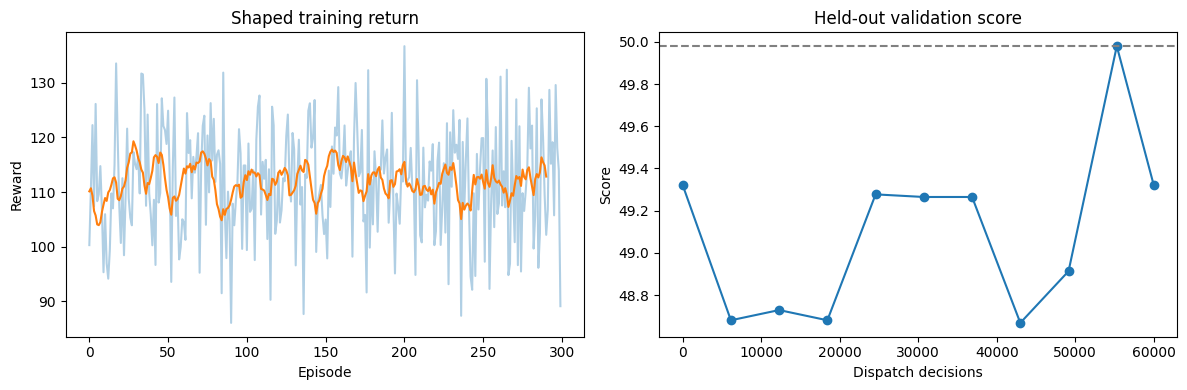

In [9]:
# Stage 2 — PPO/GAE updates; tracks the best CHECKPOINT on held-out validation seeds.
TOTAL_DECISIONS = 60_000    # increase to 100_000 for a more thorough run
HORIZON = 768
MINIBATCH = 192
PPO_EPOCHS = 4
GAMMA,LAMBDA = .993,.95
CLIP_EPS=.18
VALUE_COEF=.4
ENTROPY_COEF=.004
TARGET_KL=.035
UPDATES = math.ceil(TOTAL_DECISIONS/HORIZON)

train_env=CallAwareLiftSim(seed=42)
obs=train_env.observation()
training_returns=[]
val_history=[(0,best_val)]
episode_reward=0.0
for update in trange(UPDATES,desc='Train PPO'):
    size=min(HORIZON,TOTAL_DECISIONS-update*HORIZON)
    buffer=[]
    for _ in range(size):
        mask,prior,features=train_env.action_info()
        a,logp,value=agent_choice(obs,mask,prior,features)
        next_obs,reward,done,_=train_env.step(a)
        episode_reward+=reward
        buffer.append((obs.copy(),mask.copy(),prior.copy(),features.copy(),
                       a,logp,value,reward,done))
        obs=next_obs
        if done:
            training_returns.append(episode_reward)
            episode_reward=0.
            obs=train_env.reset()

    # Correct GAE at rollout boundary: bootstrap if last step was not terminal.
    with torch.no_grad():
        _,end_val=agent(torch.as_tensor(obs,dtype=torch.float32,device=DEVICE)[None],
                        torch.as_tensor(train_env.action_info()[2],dtype=torch.float32,device=DEVICE)[None])
        end_val=float(end_val.item())
    adv=np.zeros(size,dtype=np.float32)
    next_value=end_val
    gae=0.
    for t in reversed(range(size)):
        state,mask,prior,features,a,lp,v,r,done=buffer[t]
        nonterm=1.0-float(done)
        delta=r+GAMMA*next_value*nonterm-v
        gae=delta+GAMMA*LAMBDA*nonterm*gae
        adv[t]=gae
        next_value=v

    states=torch.as_tensor(np.stack([r[0] for r in buffer]),dtype=torch.float32,device=DEVICE)
    masks=torch.as_tensor(np.stack([r[1] for r in buffer]),dtype=torch.bool,device=DEVICE)
    priors=torch.as_tensor(np.stack([r[2] for r in buffer]),dtype=torch.float32,device=DEVICE)
    feat=torch.as_tensor(np.stack([r[3] for r in buffer]),dtype=torch.float32,device=DEVICE)
    actions=torch.as_tensor([r[4] for r in buffer],dtype=torch.long,device=DEVICE)
    oldlp=torch.as_tensor([r[5] for r in buffer],dtype=torch.float32,device=DEVICE)
    oldvalue=torch.as_tensor([r[6] for r in buffer],dtype=torch.float32,device=DEVICE)
    advantages=torch.as_tensor(adv,dtype=torch.float32,device=DEVICE)
    targets=oldvalue+advantages
    normalized=(advantages-advantages.mean())/(advantages.std(unbiased=False)+1e-8)
    agent.train()
    stop=False
    for epoch in range(PPO_EPOCHS):
        for ix in torch.randperm(size,device=DEVICE).split(MINIBATCH):
            dist,v=agent.distribution(states[ix],masks[ix],priors[ix],feat[ix])
            new_lp=dist.log_prob(actions[ix])
            ratio=torch.exp((new_lp-oldlp[ix]).clamp(-20,20))
            pi=-torch.minimum(ratio*normalized[ix],
                 ratio.clamp(1-CLIP_EPS,1+CLIP_EPS)*normalized[ix]).mean()
            vf=.5*(v-targets[ix]).square().mean()
            loss=pi+VALUE_COEF*vf-ENTROPY_COEF*dist.entropy().mean()
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(agent.parameters(),.5)
            optimizer.step()
            kl=(oldlp[ix]-new_lp.detach()).mean().item()
            if kl > TARGET_KL:
                stop=True
                break
        if stop:break
    agent.eval()
    if (update+1)%8==0 or (update+1)==UPDATES:
        val=validation_score()
        val_history.append((min(TOTAL_DECISIONS,(update+1)*HORIZON),val))
        if val>best_val:
            best_val=val
            best_weights=copy.deepcopy(agent.state_dict())
        print(f'Update {update+1}/{UPDATES}: val={val:.2f} best={best_val:.2f} training_eps={len(training_returns)}')

train_env.close()
agent.load_state_dict(best_weights)
agent.eval()
CKPT='LiftSim_PPO_Improved_best.pt'
torch.save({'model_state_dict':best_weights,'obs_dim':probe.obs_dim,
            'action_dim':probe.A,'feat_dim':probe.FEAT_DIM,
            'best_validation_score':best_val,'seed':42,
            'config_file':CONFIG_FILE,'algorithm':'masked_pairwise_PPO_GAE'},CKPT)
print('Saved BEST PPO policy:',CKPT)

fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].plot(training_returns,alpha=.35)
if len(training_returns)>=10:
    axs[0].plot(np.convolve(training_returns,np.ones(10)/10,mode='valid'))
axs[0].set(title='Shaped training return',xlabel='Episode',ylabel='Reward')
axs[1].plot(*zip(*val_history),marker='o')
axs[1].axhline(best_val,color='gray',ls='--')
axs[1].set(title='Held-out validation score',xlabel='Dispatch decisions',ylabel='Score')
plt.tight_layout()
plt.savefig('LiftSim_PPO_learning_curves.png',dpi=150)
plt.show()


Paired 30-seed evaluation: 100%|██████████| 30/30 [00:07<00:00,  4.13it/s]


raw_reward        delivered        abandoned       \
                           mean    std      mean    std      mean  std   
policy                                                                   
Expert                   -0.444  0.078    83.767  8.897       0.0  0.0   
PPO                      -0.448  0.083    84.167  8.514       0.0  0.0   
Random (valid calls)     -0.529  0.098    79.867  8.123       0.0  0.0   

                     waiting_seconds               energy             
                                mean      std        mean        std  
policy                                                                
Expert                      4000.450  797.443  882861.831  55858.368  
PPO                         4042.350  844.887  883209.474  54187.554  
Random (valid calls)        4793.733  990.870  993627.327  63750.774


PPO vs Random — 95% paired bootstrap CI
raw_reward          Δ=    +0.081 95% CI [+0.067, +0.095] PPO win rate=96.7%
delivered           Δ=    +4.300 95% CI [+3.233, +5.467] PPO win rate=93.3%
abandoned           Δ=    +0.000 95% CI [+0.000, +0.000] PPO win rate=0.0%
waiting_seconds     Δ=  -751.383 95% CI [-893.456, -617.033] PPO win rate=96.7%
energy              Δ=-110417.853 95% CI [-127684.357, -93794.539] PPO win rate=100.0%

PPO throughput improvement: +5.38%
PASS: PPO beats random


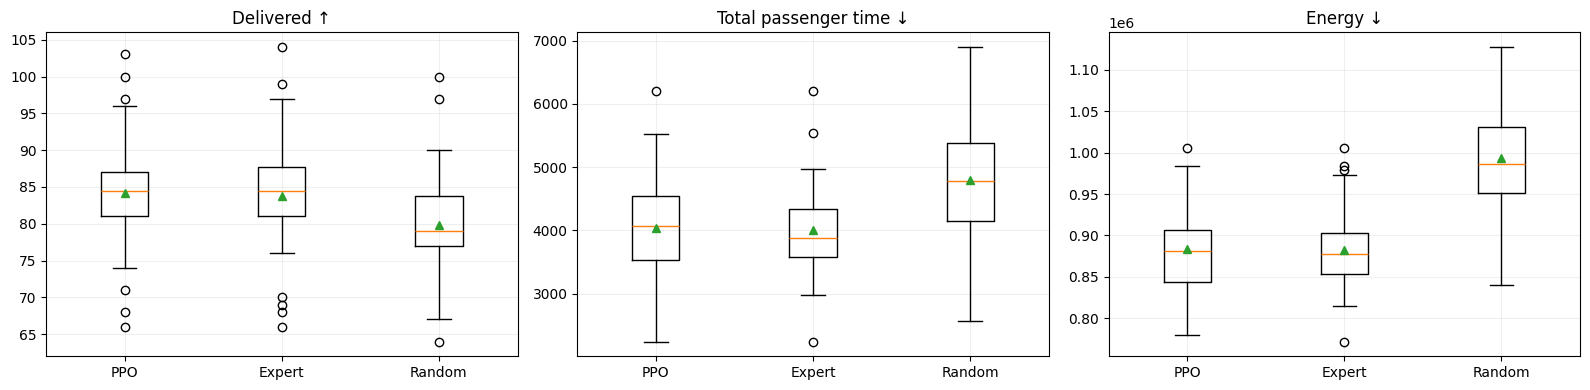

In [11]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

TEST_SEEDS = list(range(12001, 12031))
POLICIES = ["PPO", "Expert", "Random (valid calls)"]

all_rows = []

for seed in tqdm(TEST_SEEDS, desc="Paired 30-seed evaluation"):
    for policy in POLICIES:
        r = evaluate_episode(policy, seed)
        s = r["stats"]

        all_rows.append({
            "seed": seed,
            "policy": policy,
            "raw_reward": r["return"],
            "delivered": s["DeliveredPersons(10Minutes)"],
            "generated": s["GeneratedPersons(10Minutes)"],
            "abandoned": s["AbandonedPersons(10Minutes)"],
            "waiting_seconds": s["TotalWaitingTime(10Minutes)"],
            "energy": s["EnergyConsumption(10Minutes)"],
            "validation_objective": score_of(r),
        })

results = pd.DataFrame(all_rows)
results.to_csv("LiftSim_PPO_Improved_30seed_results.csv", index=False)

metrics = [
    "raw_reward", "delivered", "abandoned",
    "waiting_seconds", "energy"
]

summary = (
    results.groupby("policy")[metrics]
    .agg(["mean", "std"])
    .round(3)
)

display(summary)

wide = results.pivot(index="seed", columns="policy")
rng_ci = np.random.default_rng(2026)

print("\nPPO vs Random — 95% paired bootstrap CI")

for metric in metrics:
    d = (
        wide[(metric, "PPO")]
        - wide[(metric, "Random (valid calls)")]
    ).to_numpy(dtype=float)

    samples = rng_ci.choice(
        d, size=(10000, len(d)), replace=True
    ).mean(axis=1)

    low, high = np.quantile(samples, [0.025, 0.975])

    higher_is_better = metric in ["delivered", "raw_reward"]
    win_rate = (
        (d > 0).mean() if higher_is_better
        else (d < 0).mean()
    ) * 100

    print(
        f"{metric:<19} Δ={d.mean():+10.3f} "
        f"95% CI [{low:+.3f}, {high:+.3f}] "
        f"PPO win rate={win_rate:.1f}%"
    )

avg = results.groupby("policy")[metrics].mean()

ppo_delivered = avg.loc["PPO", "delivered"]
random_delivered = avg.loc["Random (valid calls)", "delivered"]

improvement = (
    (ppo_delivered / random_delivered - 1) * 100
    if random_delivered > 0 else float("nan")
)

print(f"\nPPO throughput improvement: {improvement:+.2f}%")

print(
    "PASS: PPO beats random"
    if ppo_delivered > random_delivered
    else "FAIL: PPO did not beat random"
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, metric, title in zip(
    axes,
    ["delivered", "waiting_seconds", "energy"],
    ["Delivered ↑", "Total passenger time ↓", "Energy ↓"]
):
    groups = [
        results.loc[results.policy == p, metric].values
        for p in POLICIES
    ]

    ax.boxplot(groups, showmeans=True)
    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(["PPO", "Expert", "Random"])
    ax.set_title(title)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig("LiftSim_PPO_Improved_comparison.png", dpi=160)
plt.show()


PPO: delivered=77, raw reward=-0.423
Random: delivered=73, raw reward=-0.544


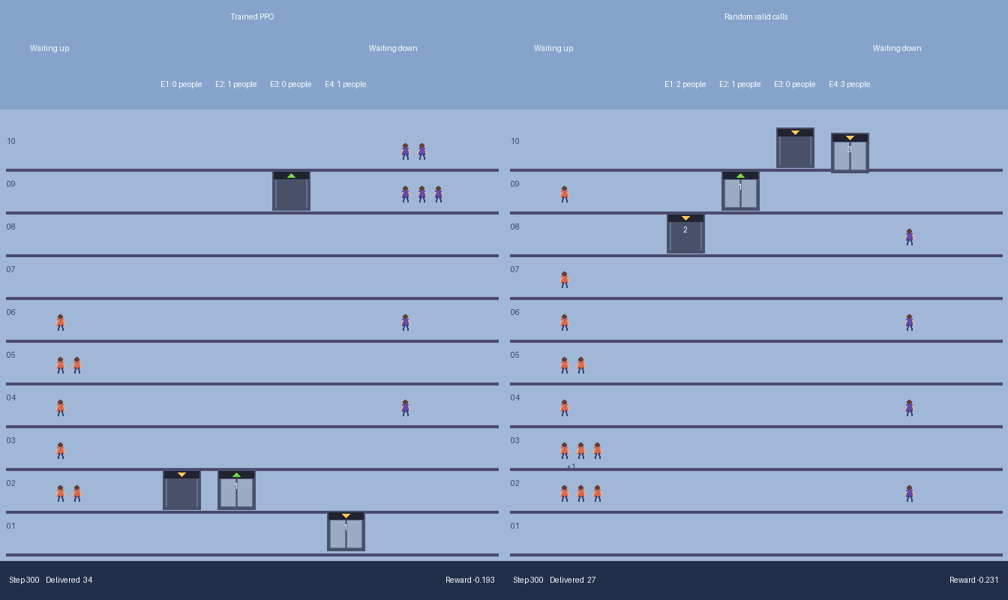

In [12]:
# PIL renderer similar to LiftSim's original blue-building scene.
from PIL import Image, ImageDraw, ImageFont

PANEL_W, PANEL_H = 672, 800
FRAME_W, FRAME_H = PANEL_W * 2, PANEL_H
BLUE = (160, 183, 215)
LINE = (77, 73, 111)
SHAFT = (126, 150, 185)
CAR = (127, 144, 172)
DOOR = (155, 171, 196)
TEXT = (255, 255, 255)
FLOOR_Y0 = 710  # y-position of the center of floor 1
FLOOR_GAP = 57
CAR_X = [242, 315, 388, 461]

def font(sz, bold=False):
    f = '/usr/share/fonts/truetype/dejavu/DejaVuSans' + ('-Bold.ttf' if bold else '.ttf')
    try:
        return ImageFont.truetype(f, sz)
    except OSError:
        return ImageFont.load_default()

FONT_13, FONT_15 = font(13), font(15)
FONT_18, FONT_22 = font(18, True), font(22, True)

def draw_person(d, x, y, tint=(224, 99, 78), scale=1.0):
    """Little standing human silhouette to represent a waiting passenger."""
    r = lambda n: max(1, round(n*scale))
    x, y = int(x), int(y)
    d.ellipse((x-r(4), y-r(18), x+r(4), y-r(10)), fill=(105, 64, 57))
    d.rectangle((x-r(5), y-r(10), x+r(5), y+r(1)), fill=tint)
    d.line((x-r(3), y, x-r(4), y+r(9)), fill=(53, 61, 109), width=r(3))
    d.line((x+r(3), y, x+r(4), y+r(9)), fill=(53, 61, 109), width=r(3))
    d.line((x-r(6), y-r(8), x-r(8), y-r(1)), fill=(224, 183, 152), width=r(2))
    d.line((x+r(6), y-r(8), x+r(8), y-r(1)), fill=(224, 183, 152), width=r(2))

def y_for_floor(floor):
    return FLOOR_Y0 - (float(floor)-1) * FLOOR_GAP

def draw_car(d, cx, floor, car, idn):
    y = y_for_floor(car['floor'])
    w, h = 46, 49
    x0, y0 = int(cx-w/2), int(y-h/2)
    d.rectangle((x0-2, y0-2, x0+w+2, y0+h+2), fill=(72, 80, 112))
    d.rectangle((x0, y0+9, x0+w, y0+h), fill=(73, 80, 103))
    door_open = min(1., max(0., car['door']))
    half = max(1, int((w-5)*(1-door_open)/2))
    if half > 0:
        d.rectangle((x0+2, y0+10, x0+2+half, y0+h-2), fill=DOOR, outline=(100, 113, 147))
        d.rectangle((x0+w-2-half, y0+10, x0+w-2, y0+h-2), fill=DOOR, outline=(100, 113, 147))
    d.rectangle((x0, y0, x0+w, y0+9), fill=(33, 35, 48))
    direction = car['direction']
    arrow = (114, 222, 69) if direction > 0 else (255, 200, 91) if direction < 0 else (114, 120, 132)
    if direction >= 0:
        d.polygon([(cx-5, y0+7),(cx, y0+2),(cx+5, y0+7)], fill=arrow)
    else:
        d.polygon([(cx-5, y0+2),(cx, y0+7),(cx+5, y0+2)], fill=arrow)
    if car['load']:
        d.text((cx, y0+20), str(car['load']), font=FONT_13, fill=TEXT, anchor='mm')

def draw_panel(img, x_offset, frame, title):
    d = ImageDraw.Draw(img)
    left = x_offset
    d.rectangle((left, 0, left+PANEL_W-1, PANEL_H-1), fill=BLUE)
    d.rectangle((left, 0, left+PANEL_W-1, 145), fill=(133, 163, 203))
    d.text((left+PANEL_W//2, 18), title, font=FONT_22, fill=TEXT, anchor='mt')
    d.text((left+40, 58), 'Waiting up', font=FONT_18, fill=TEXT)
    d.text((left+PANEL_W-180, 58), 'Waiting down', font=FONT_18, fill=TEXT)
    for i, cx in enumerate(CAR_X):
        d.text((left+cx, 108), f'E{i+1}: {frame["cars"][i]["load"]} people',
               font=FONT_13, fill=TEXT, anchor='mt')
    # floor stripes + floors + hallway walls
    for floor in range(1, len(frame['up'])+1):
        y = int(y_for_floor(floor))
        d.line((left+8, y+29, left+PANEL_W-8, y+29), fill=LINE, width=4)
        d.text((left+9, y-15), f'{floor:02}', font=FONT_13, fill=(54, 68, 99))
        up_n = frame['up'][floor-1]
        down_n = frame['down'][floor-1]
        for k in range(min(3, up_n)):
            draw_person(d, left+80+k*22, y+8, tint=(215, 106, 82), scale=0.75)
        for k in range(min(3, down_n)):
            draw_person(d, left+540+k*22, y+8, tint=(99, 76, 173), scale=0.75)
        if up_n > 3:
            d.text((left+83, y+20), f'+{up_n-3}', font=FONT_13, fill=(54, 68, 99))
        if down_n > 3:
            d.text((left+557, y+20), f'+{down_n-3}', font=FONT_13, fill=(54, 68, 99))
    for i, car in enumerate(frame['cars']):
        draw_car(d, left+CAR_X[i], car['floor'], car, i)
    d.rectangle((left+0, PANEL_H-52, left+PANEL_W-1, PANEL_H-1), fill=(34, 47, 74))
    delivered = frame['stats'].get('DeliveredPersons(10Minutes)', 0)
    d.text((left+12, PANEL_H-33), f'Step {frame["step"]:3}    Delivered {delivered:3}',
           font=FONT_15, fill=TEXT)
    d.text((left+PANEL_W-12, PANEL_H-33), f'Reward {frame["reward"]:.3f}',
           font=FONT_15, fill=TEXT, anchor='ra')

def render_frame(a, b):
    img = Image.new('RGB', (FRAME_W, FRAME_H))
    draw_panel(img, 0, a, 'Trained PPO')
    draw_panel(img, PANEL_W, b, 'Random valid calls')
    return img



VIDEO_SEED=12040  # deliberately outside training, validation and final 30-seed evaluation
ppo_video=evaluate_episode('PPO',VIDEO_SEED,record=True)
rand_video=evaluate_episode('Random (valid calls)',VIDEO_SEED,record=True)
print(f"PPO: delivered={ppo_video['stats']['DeliveredPersons(10Minutes)']}, raw reward={ppo_video['return']:.3f}")
print(f"Random: delivered={rand_video['stats']['DeliveredPersons(10Minutes)']}, raw reward={rand_video['return']:.3f}")
preview_at=min(300,len(ppo_video['frames'])-1)
display(render_frame(ppo_video['frames'][preview_at],rand_video['frames'][preview_at]).resize((1008,600)))


In [13]:
# Every physical tick is drawn; 5 fps = 2.5× simulated speed (slow enough to watch).
VIDEO_FPS=5
RENDER_EVERY=1
VIDEO_PATH='LiftSim_PPO_Improved_vs_Random.mp4'
end=min(len(ppo_video['frames']),len(rand_video['frames']))
with imageio.get_writer(VIDEO_PATH,fps=VIDEO_FPS,codec='libx264',quality=7,macro_block_size=16) as writer:
    for t in trange(0,end,RENDER_EVERY,desc='Create side-by-side video'):
        writer.append_data(np.asarray(render_frame(ppo_video['frames'][t],rand_video['frames'][t])))
print('Saved video:',VIDEO_PATH,os.path.getsize(VIDEO_PATH),'bytes')
display(Video(VIDEO_PATH,embed=True,width=1200))


Create side-by-side video: 100%|██████████| 601/601 [00:04<00:00, 135.34it/s]

Saved video: LiftSim_PPO_Improved_vs_Random.mp4 959469 bytes


### Generated files
- `LiftSim_PPO_Improved_best.pt` — selected PPO weights (load with `PairwisePPO` class and `state_dict`).
- `LiftSim_PPO_Improved_30seed_results.csv` — every held-out paired score, no hidden test exclusions.
- `LiftSim_PPO_Improved_comparison.png` — delivery, waiting, energy boxplots.
- `LiftSim_PPO_Improved_learning_curves.png` — PPO optimization curves.
- `LiftSim_PPO_Improved_vs_Random.mp4` — side-by-side animation using each car's real fractional-floor position.

If PPO fails the throughput check, it is **still the trained PPO checkpoint**; the notebook never substitutes an expert policy while claiming it is PPO.
